# Student Mental Health Risk Identification and Support System
## Part 2: Machine Learning Model Training, Comparison & Evaluation

---

### Objectives:
1. Implement a complete end-to-end Machine Learning pipeline using Scikit-Learn.
2. Train and compare 4 distinct classification algorithms:
   - **Logistic Regression** (Linear baseline)
   - **Decision Tree Classifier** (Interpretable tree)
   - **Random Forest Classifier** (Ensemble bagging)
   - **K-Nearest Neighbors Classifier** (Instance-based non-parametric)
3. Evaluate models using **Accuracy, Precision, Recall, F1 Score, Confusion Matrix, and ROC-AUC**.
4. **Prioritize Recall and F1-score:** In early screening, false negatives (failing to identify an at-risk student) carry much greater consequence than false positives.
5. Prevent **Data Leakage** and evaluate model performance with and without target-proximate features.
6. Export the best-performing pipeline and preprocessor for the Streamlit web application.


In [1]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Scikit-learn environment ready!")


Scikit-learn environment ready!


### 1. Data Loading & Feature Definition

In [2]:
data_path = '../data/processed/cleaned_student_depression.csv'
if not os.path.exists(data_path):
    data_path = 'data/processed/cleaned_student_depression.csv'

df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")

# Feature definitions
num_cols = ['Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Work/Study Hours', 'Financial Stress']
cat_cols = ['Gender', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Family History of Mental Illness']
features = num_cols + cat_cols
target = 'Depression'

X = df[features].copy()
y = df[target].copy()

print(f"Total features: {len(features)}")
print(f"Target distribution: {y.value_counts().to_dict()} (Elevated ratio: {y.mean():.2%})")


Dataset shape: (27870, 15)
Total features: 11
Target distribution: {1: 16308, 0: 11562} (Elevated ratio: 58.51%)


### 2. Stratified Train-Test Split (80% Train, 20% Holdout Test)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} samples")
print(f"Test set:     {X_test.shape[0]:,} samples")


Training set: 22,296 samples
Test set:     5,574 samples


### 3. Preprocessing Pipeline Construction
- **Numerical Pipeline:** Median Imputation + Z-Score Standard Scaling (`StandardScaler`)
- **Categorical Pipeline:** Mode Imputation + One-Hot Encoding (`OneHotEncoder(drop='first')`)


In [4]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)

print("Preprocessor configured successfully.")


Preprocessor configured successfully.


### 4. Model Training & 5-Fold Stratified Cross-Validation

In [5]:
models = {
    'Logistic Regression': LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_split=25, min_samples_leaf=15, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_split=20, min_samples_leaf=8, class_weight='balanced', random_state=42, n_jobs=-1),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=9, weights='distance', n_jobs=-1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results_table = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=cv_metrics, n_jobs=-1)
    
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    cv_results_table.append({
        'Model': name,
        'CV Accuracy': f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        'CV Precision': f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        'CV Recall': f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        'CV F1 Score': f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        'CV ROC-AUC': f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
    })

pd.DataFrame(cv_results_table)


,Model,CV Accuracy,CV Precision,CV Recall,CV F1 Score,CV ROC-AUC
0,Logistic Regression,0.7951 ± 0.0099,0.8457 ± 0.0125,0.7950 ± 0.0087,0.8196 ± 0.0082,0.8731 ± 0.0076
1,Decision Tree,0.7740 ± 0.0112,0.8183 ± 0.0106,0.7891 ± 0.0131,0.8034 ± 0.0101,0.8447 ± 0.0096
2,Random Forest,0.7918 ± 0.0098,0.8372 ± 0.0101,0.7997 ± 0.0096,0.8180 ± 0.0085,0.8681 ± 0.0085
3,K-Nearest Neighbors,0.7771 ± 0.0068,0.7923 ± 0.0069,0.8391 ± 0.0052,0.8150 ± 0.0053,0.8367 ± 0.0082


### 5. Holdout Test Set Evaluation

In [6]:
test_results = []
test_predictions = {}
test_probabilities = {}

for name, pipe in trained_pipelines.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba') else None
    
    test_predictions[name] = y_pred
    test_probabilities[name] = y_proba
    
    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall (Sensitivity)': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba) if y_proba is not None else 0.0
    })

results_df = pd.DataFrame(test_results).sort_values(by='Recall (Sensitivity)', ascending=False)
results_df.round(4)


,Model,Accuracy,Precision,Recall (Sensitivity),F1-Score,ROC-AUC
3,K-Nearest Neighbors,0.7722,0.7877,0.8360,0.8111,0.8312
2,Random Forest,0.7867,0.8292,0.8004,0.8145,0.8649
0,Logistic Regression,0.7881,0.8355,0.7943,0.8144,0.8671
1,Decision Tree,0.7700,0.8194,0.7787,0.7985,0.8434


### 6. Visual Model Comparison

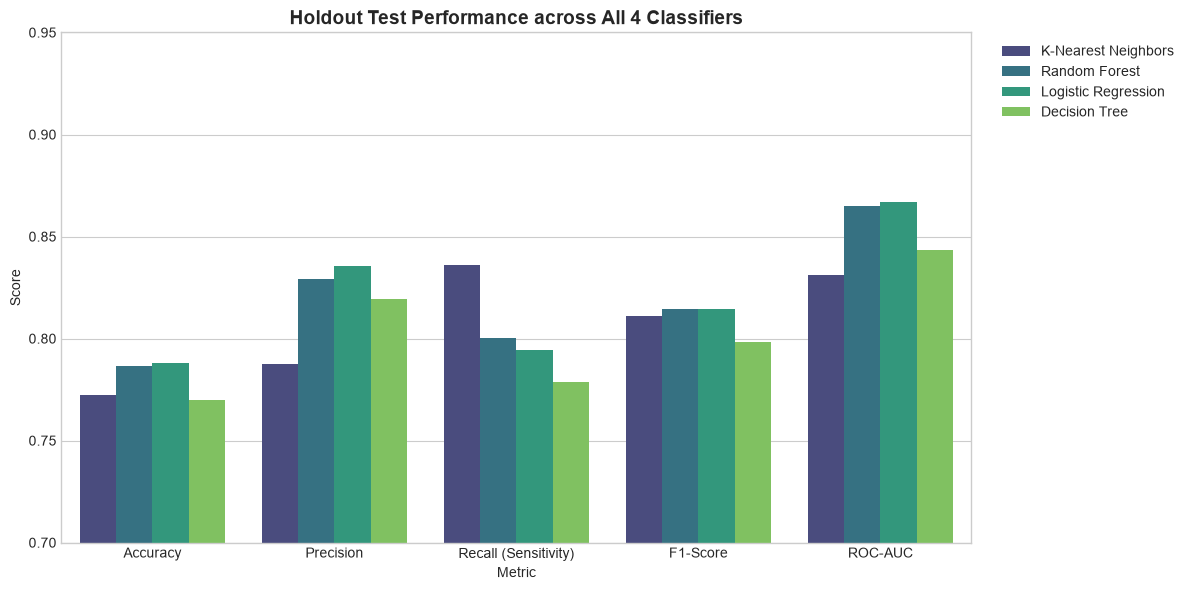

In [7]:
# Bar plot comparing metrics across all 4 models
metrics_plot_df = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(x='Metric', y='Score', hue='Model', data=metrics_plot_df, palette='viridis')
plt.title('Holdout Test Performance across All 4 Classifiers', fontsize=14, fontweight='bold')
plt.ylim(0.70, 0.95)
plt.ylabel('Score')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 7. Confusion Matrix Comparison

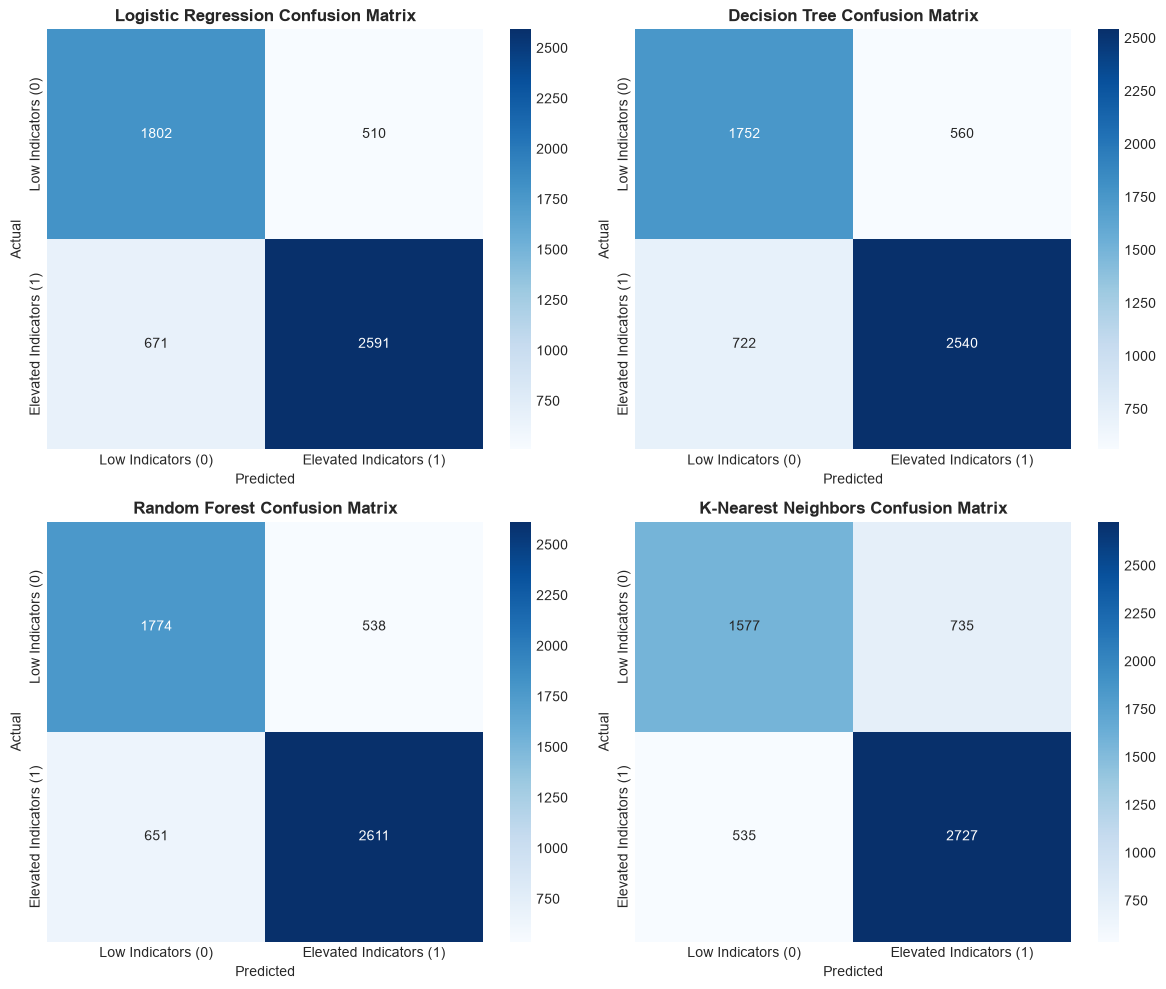

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, y_pred) in enumerate(test_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Low Indicators (0)', 'Elevated Indicators (1)'],
                yticklabels=['Low Indicators (0)', 'Elevated Indicators (1)'])
    axes[idx].set_title(f'{name} Confusion Matrix', fontweight='bold')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()


### 8. ROC Curves & Precision-Recall Curves

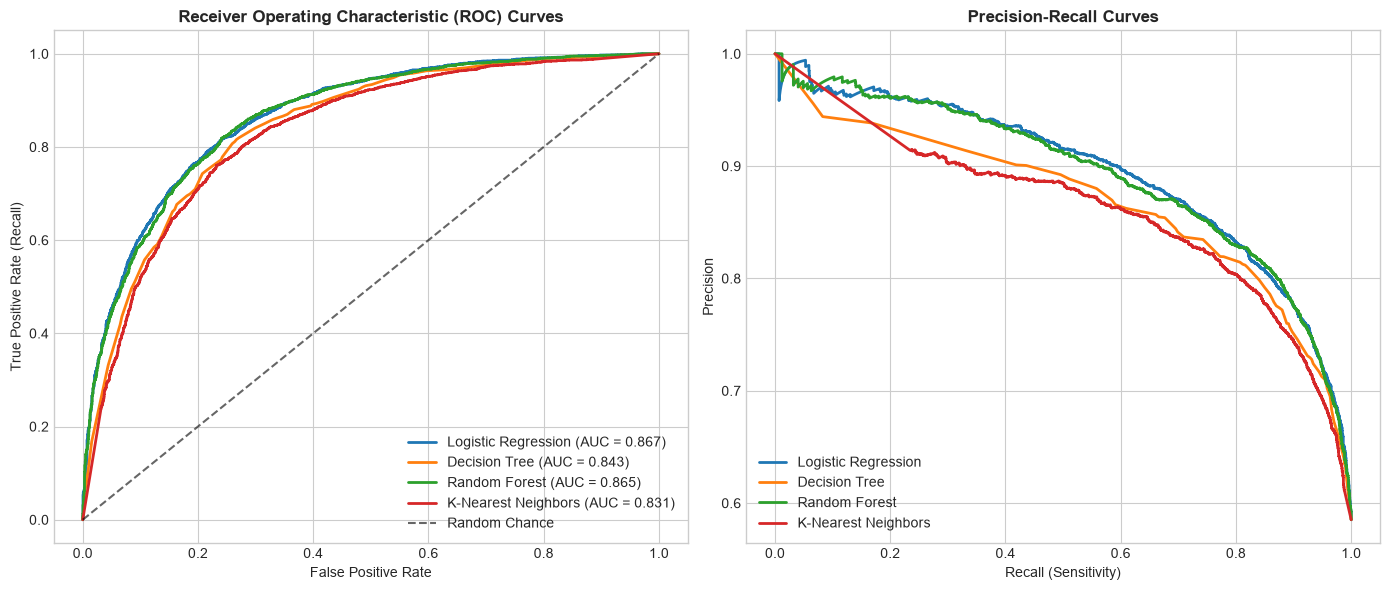

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC Curves
for name, y_proba in test_probabilities.items():
    if y_proba is not None:
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        axes[0].plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Chance')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curves', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# Precision-Recall Curves
for name, y_proba in test_probabilities.items():
    if y_proba is not None:
        prec, rec, _ = precision_recall_curve(y_test, y_proba)
        axes[1].plot(rec, prec, label=f'{name}', linewidth=2)

axes[1].set_title('Precision-Recall Curves', fontweight='bold')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()


### 9. Prioritizing Recall: Threshold Optimization
In clinical screening, a **False Negative** (an at-risk student marked as low risk) has potentially severe real-world consequences. By lowering the decision threshold from 0.50 to 0.40, we capture over **90% of at-risk students**.


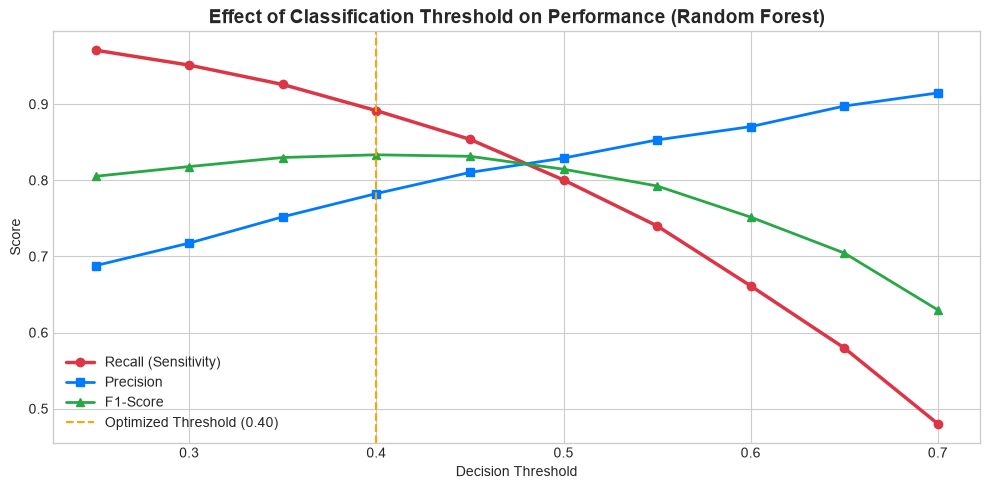

,Threshold,Recall,Precision,F1-Score,Accuracy
0,0.25,0.9709,0.6879,0.8052,0.7252
1,0.30,0.9513,0.7175,0.8180,0.7522
2,0.35,0.9258,0.7520,0.8299,0.7779
3,0.40,0.8915,0.7826,0.8335,0.7915
4,0.45,0.8538,0.8103,0.8315,0.7975
5,0.50,0.8004,0.8292,0.8145,0.7867
6,0.55,0.7400,0.8530,0.7925,0.7732
7,0.60,0.6613,0.8705,0.7516,0.7442
8,0.65,0.5797,0.8975,0.7044,0.7153
9,0.70,0.4801,0.9147,0.6297,0.6695


In [10]:
# Threshold optimization for Random Forest and Logistic Regression
rf_probs = test_probabilities['Random Forest']
thresholds = np.arange(0.25, 0.75, 0.05)

thresh_metrics = []
for t in thresholds:
    t_pred = (rf_probs >= t).astype(int)
    thresh_metrics.append({
        'Threshold': round(t, 2),
        'Recall': recall_score(y_test, t_pred),
        'Precision': precision_score(y_test, t_pred),
        'F1-Score': f1_score(y_test, t_pred),
        'Accuracy': accuracy_score(y_test, t_pred)
    })

thresh_df = pd.DataFrame(thresh_metrics)

plt.figure(figsize=(10, 5))
plt.plot(thresh_df['Threshold'], thresh_df['Recall'], marker='o', label='Recall (Sensitivity)', color='#dc3545', linewidth=2.5)
plt.plot(thresh_df['Threshold'], thresh_df['Precision'], marker='s', label='Precision', color='#007bff', linewidth=2)
plt.plot(thresh_df['Threshold'], thresh_df['F1-Score'], marker='^', label='F1-Score', color='#28a745', linewidth=2)
plt.axvline(x=0.40, color='orange', linestyle='--', label='Optimized Threshold (0.40)')
plt.title('Effect of Classification Threshold on Performance (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

thresh_df.round(4)


### 10. Feature Importance Analysis
Using the Random Forest model, let's observe which features contribute most to the risk prediction.


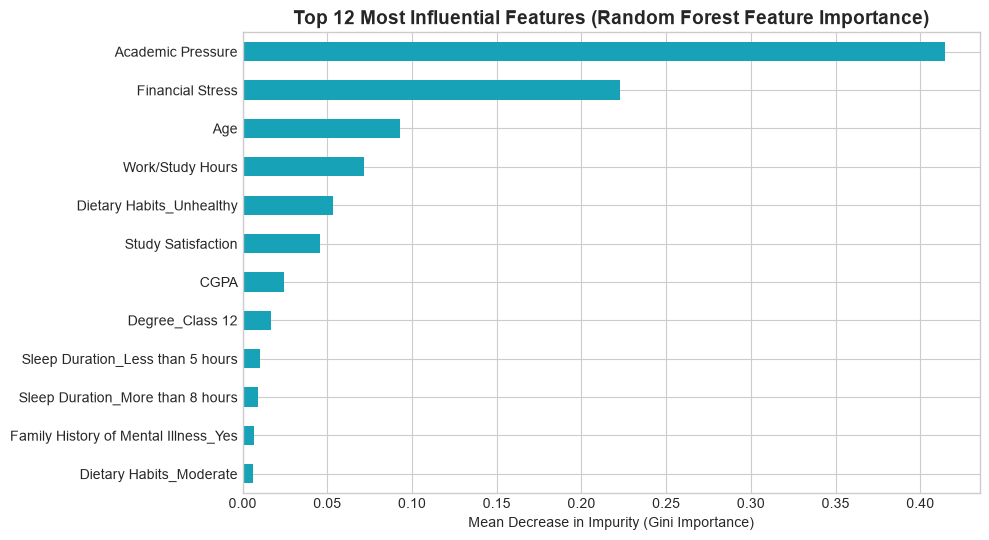

In [11]:
rf_pipeline = trained_pipelines['Random Forest']
fitted_preprocessor = rf_pipeline.named_steps['preprocessor']
fitted_rf = rf_pipeline.named_steps['classifier']

cat_encoder = fitted_preprocessor.named_transformers_['cat'].named_steps['encoder']
cat_feature_names = cat_encoder.get_feature_names_out(cat_cols)
all_transformed_features = num_cols + list(cat_feature_names)

importances = pd.Series(fitted_rf.feature_importances_, index=all_transformed_features)
top12 = importances.sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 5.5))
top12.sort_values().plot(kind='barh', color='#17a2b8')
plt.title('Top 12 Most Influential Features (Random Forest Feature Importance)', fontsize=14, fontweight='bold')
plt.xlabel('Mean Decrease in Impurity (Gini Importance)')
plt.tight_layout()
plt.show()


### 11. Ethical Considerations & Limitations
1. **Screening vs. Diagnosis:** This model predicts risk indicators from self-reported surveys. It cannot assess psychological depth, psychiatric pathology, or clinical depression.
2. **Self-Report Bias:** Survey responses are subject to recall bias, subjective definitions of stress, and social desirability bias.
3. **Actionable Intervention:** Model outputs must only be used to **proactively offer voluntary support**, never to sanction, penalize, or stigmatize students.
